# Guía del proyecto: semáforo con aprendizaje por refuerzo

Este notebook recorre el proyecto de punta a punta usando el mismo código de `src/`.
No reemplaza a los scripts (los resultados oficiales salen de `scripts/evaluate.py`);
sirve para **entender qué hace cada parte** y como guion para la defensa.

**No modifica ningún archivo del repo**: solo lee datos, modelos y resultados.

Contenido:
1. Qué es el aprendizaje por refuerzo y en qué se diferencia de lo visto en el curso
2. El simulador del cruce
3. Los dos controladores de referencia
4. Q-learning: una actualización a mano y un entrenamiento chico
5. DQN: qué responde la red entrenada
6. Resultados del experimento
7. Los datos de Montevideo

## 1. Aprendizaje por refuerzo

En las entregas 1 y 2 usamos **aprendizaje supervisado**: cada ejemplo tenía la respuesta correcta
(si el reclamo se cerró a tiempo) y el modelo aprendía a predecirla.

En **aprendizaje por refuerzo** no hay respuesta correcta:

| | Supervisado | Por refuerzo |
|---|---|---|
| Qué recibe | Ejemplos con etiqueta | Una recompensa después de actuar |
| Qué aprende | A predecir la etiqueta | Una **política**: qué acción tomar en cada situación |
| Los datos | Fijos de antemano | Dependen de las acciones que toma el agente |

En nuestro caso:
- **Agente**: el semáforo.
- **Estado / observación**: las dos colas, qué calle tiene verde, hace cuánto y el tiempo del episodio.
- **Acciones**: `0` mantener la fase, `1` pedir un cambio (cada 5 segundos).
- **Recompensa**: menos la cantidad de autos esperando. Maximizarla es minimizar la espera.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.environment import TrafficEnv, arrivals_for
from src.controllers import FixedController, QueueController
from src.q_learning import QLearning, encode
from src.dqn import DQN
from src.experiment import run_episode

## 2. El simulador

Un episodio dura 600 segundos. Las llegadas de autos se sortean **antes** de empezar (distribución de Poisson),
así todos los controladores enfrentan exactamente el mismo tránsito.

Reglas del cruce: verde mínimo 10 s, verde máximo 60 s, 3 s de transición en la que nadie cruza,
y con verde cruza 1 auto por segundo.

In [2]:
llegadas = arrivals_for('cambiante', seed=0, horizon=600)
print('Forma de la matriz de llegadas:', llegadas.shape, '(segundos x calles)')
print('Autos que llegan a A en la primera mitad:', llegadas[:300, 0].sum())
print('Autos que llegan a B en la primera mitad:', llegadas[:300, 1].sum())
print('Autos que llegan a A en la segunda mitad:', llegadas[300:, 0].sum())
print('Autos que llegan a B en la segunda mitad:', llegadas[300:, 1].sum())

Forma de la matriz de llegadas: (600, 2) (segundos x calles)
Autos que llegan a A en la primera mitad: 137
Autos que llegan a B en la primera mitad: 39
Autos que llegan a A en la segunda mitad: 30
Autos que llegan a B en la segunda mitad: 109


Un paso del entorno: el controlador elige una acción y el simulador avanza 5 segundos.

In [3]:
env = TrafficEnv()
obs = env.reset('cambiante', seed=0)
print('Observación inicial:', obs)
for _ in range(4):
    obs, recompensa, termino = env.step(0)   # mantener
print('Después de 20 segundos manteniendo la fase:')
print('  observación:', np.round(obs, 3))
print('  colas (A, B):', len(env.queues[0]), len(env.queues[1]))
print('  recompensa del último paso:', recompensa)

Observación inicial: [0. 0. 0. 0. 0.]
Después de 20 segundos manteniendo la fase:
  observación: [0.    0.075 0.    0.333 0.033]
  colas (A, B): 0 3
  recompensa del último paso: -0.15


## 3. Controladores de referencia

- **Fijo**: 15 segundos de verde para cada calle (la duración se eligió en validación).
- **Mayor cola**: pide cambiar cuando la otra calle tiene más autos.

Los dos se corren sobre el mismo episodio y se compara la espera media por auto.

In [4]:
for nombre, controlador in [('Fijo 15 s', FixedController(15)), ('Mayor cola', QueueController())]:
    metricas, _ = run_episode(controlador, 'cambiante', seed=0)
    print(f"{nombre:12s} espera media: {metricas['mean_observed_wait']:5.2f} s  "
          f"cambios: {metricas['switches']}  autos pendientes al final: {metricas['pending']}")

Fijo 15 s    espera media: 21.69 s  cambios: 30  autos pendientes al final: 8
Mayor cola   espera media:  9.73 s  cambios: 33  autos pendientes al final: 4


## 4. Q-learning

### 4.1 Una actualización a mano

La tabla Q tiene un valor por cada estado (observación agrupada en intervalos) y cada acción.
La regla de actualización es:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,[\,r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,]$$

In [5]:
agente = QLearning(seed=0)   # alpha = 0.12, gamma = 0.97, tabla en cero
print('Tamaño de la tabla:', agente.q.shape, '->', agente.q.size, 'valores')

env = TrafficEnv()
obs = env.reset('desigual', seed=1)
for _ in range(6):                      # avanzamos 30 s para que haya colas
    obs, _, _ = env.step(0)
estado = encode(obs)
print('Estado (grupo cola A, grupo cola B, fase, grupo edad, tercio):', estado)
print('Q antes:', agente.q[estado])

siguiente, r, termino = env.step(1)     # pedimos un cambio
agente.update(obs, 1, r, siguiente, termino)
print('Recompensa recibida:', r)
print('Q después:', agente.q[estado])
print('Cuenta a mano: 0 + 0.12 * (', r, '+ 0.97 * 0 - 0 ) =', round(0.12 * r, 4))

Tamaño de la tabla: (7, 7, 2, 7, 3, 2) -> 4116 valores
Estado (grupo cola A, grupo cola B, fase, grupo edad, tercio): (5, 0, 1, 3, 0)
Q antes: [0. 0.]
Recompensa recibida: -1.07
Q después: [ 0.     -0.1284]
Cuenta a mano: 0 + 0.12 * ( -1.07 + 0.97 * 0 - 0 ) = -0.1284


La recompensa siempre es negativa mientras haya autos esperando, así que el valor de la acción
probada baja. Después de miles de actualizaciones, en cada estado queda más alto el valor de la acción
que, en promedio, deja menos autos esperando de ahí en adelante. El agente elige esa.

### 4.2 Un entrenamiento chico

Entrenamos un agente durante 400 episodios (menos de un segundo). La exploración (epsilon)
empieza en 1 (todo al azar) y baja hasta 0,05. El entrenamiento oficial usa 700 episodios
y 5 semillas, y está en `scripts/train.py`; este agente no se guarda.

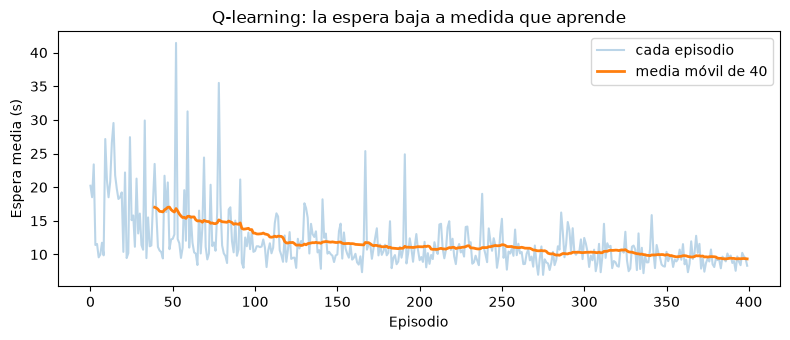

In [6]:
agente = QLearning(seed=0)
env = TrafficEnv()
rng = np.random.default_rng(0)
episodios = 400
esperas = []
for ep in range(episodios):
    escenario = ['equilibrado', 'desigual', 'cambiante'][rng.integers(3)]
    obs = env.reset(escenario, seed=ep)
    epsilon = max(0.05, 1 - ep / (0.75 * episodios))
    termino = False
    while not termino:
        accion = agente.act(obs, epsilon)
        siguiente, r, termino = env.step(accion)
        agente.update(obs, accion, r, siguiente, termino)
        obs = siguiente
    esperas.append(env.metrics()['mean_observed_wait'])

media_movil = pd.Series(esperas).rolling(40).mean()
plt.figure(figsize=(8, 3.5))
plt.plot(esperas, alpha=.3, label='cada episodio')
plt.plot(media_movil, lw=2, label='media móvil de 40')
plt.xlabel('Episodio'); plt.ylabel('Espera media (s)')
plt.title('Q-learning: la espera baja a medida que aprende')
plt.legend(); plt.tight_layout(); plt.show()

Comparamos el agente recién entrenado con las dos reglas, sin exploración y en semillas que no vio.

In [7]:
filas = []
for escenario in ['equilibrado', 'desigual', 'cambiante']:
    for nombre, controlador in [('fijo', FixedController(15)), ('mayor cola', QueueController()),
                                ('q-learning chico', agente)]:
        esperas_test = [run_episode(controlador, escenario, 900000 + i)[0]['mean_observed_wait']
                        for i in range(20)]
        filas.append(dict(escenario=escenario, controlador=nombre, espera=np.mean(esperas_test)))
pd.DataFrame(filas).pivot(index='escenario', columns='controlador', values='espera').round(2)

controlador,fijo,mayor cola,q-learning chico
escenario,,,
cambiante,14.47,8.39,9.80
desigual,16.22,8.56,9.45
equilibrado,8.99,7.45,9.98


## 5. DQN

DQN reemplaza la tabla por una red neuronal 5 → 64 → 64 → 2 que recibe la observación sin agrupar.
Cargamos uno de los modelos entrenados del repo y le preguntamos qué haría en dos situaciones.

In [8]:
red = DQN.load('models/dqn_0.pt')

def situacion(cola_a, cola_b, fase, edad):
    return np.array([cola_a / 40, cola_b / 40, fase, edad / 60, 0.5], dtype=np.float32)

casos = {
    'Verde A, 15 autos en A, 0 en B': situacion(15, 0, 0, 20),
    'Verde A, 0 autos en A, 15 en B': situacion(0, 15, 0, 20),
}
import torch
for nombre, obs in casos.items():
    with torch.no_grad():
        q = red.online(torch.from_numpy(obs)).numpy()
    accion = 'mantener' if q.argmax() == 0 else 'cambiar'
    print(f'{nombre}: Q(mantener)={q[0]:.2f}  Q(cambiar)={q[1]:.2f}  -> {accion}')

Verde A, 15 autos en A, 0 en B: Q(mantener)=-5.20  Q(cambiar)=-8.62  -> mantener
Verde A, 0 autos en A, 15 en B: Q(mantener)=-7.76  Q(cambiar)=-5.60  -> cambiar


## 6. Resultados del experimento

Estos son los resultados oficiales (`results/summary.csv`): 30 episodios por escenario;
los agentes tienen 5 versiones entrenadas con semillas distintas.

In [9]:
resumen = pd.read_csv('results/summary.csv')
tabla = resumen.pivot(index='scenario', columns='algorithm', values='mean_observed_wait')
tabla = tabla.loc[['equilibrado', 'desigual', 'cambiante', 'estres', 'montevideo'],
                  ['fijo', 'reglas', 'q_learning', 'dqn']]
tabla.round(2)

algorithm,fijo,reglas,q_learning,dqn
scenario,,,,
equilibrado,9.11,7.78,9.78,7.73
desigual,17.03,8.61,8.62,7.63
cambiante,14.95,8.48,8.93,7.66
estres,18.49,13.62,18.74,11.97
montevideo,6.96,4.13,12.74,12.50


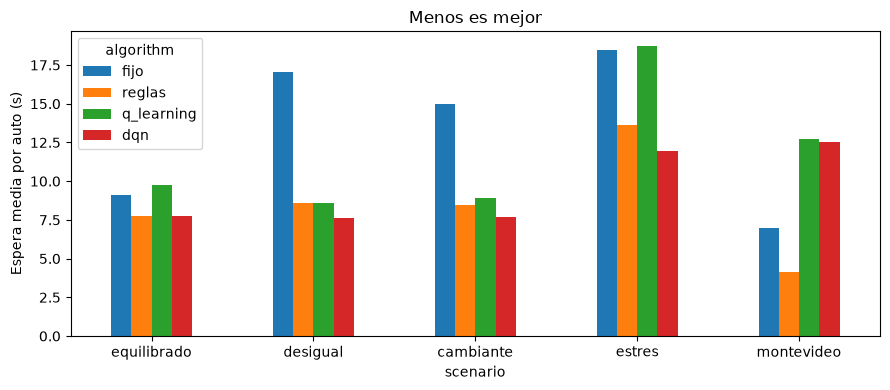

In [10]:
tabla.plot.bar(figsize=(9, 4), rot=0)
plt.ylabel('Espera media por auto (s)')
plt.title('Menos es mejor')
plt.tight_layout(); plt.show()

Lectura:
- En los escenarios sintéticos **DQN tiene la menor espera**, aunque la regla de mayor cola queda cerca.
- Q-learning mejora al fijo cuando la demanda es desigual o cambia, pero no en equilibrado ni en estrés.
- En **Montevideo gana la regla de mayor cola** y los agentes quedan peor que el fijo.

## 7. Los datos de Montevideo

Las tasas salen de los sensores de Bv Artigas y Rivera (enero de 2026): `volumen_hora` sumado por calle
y dividido entre 3600 para pasarlo a autos por segundo.

In [11]:
perfiles = pd.read_csv('data/perfiles_montevideo.csv')
print(perfiles.groupby('split')[['rate_a', 'rate_b']].mean().round(3))
print()
print('Para comparar, el escenario equilibrado usa 0.23 autos por segundo en cada calle.')

            rate_a  rate_b
split                     
test         0.027   0.016
train        0.016   0.012
validation   0.024   0.013

Para comparar, el escenario equilibrado usa 0.23 autos por segundo en cada calle.


Las tasas de Montevideo son unas **10 veces menores** que las de los escenarios sintéticos:
el cruce simulado queda casi vacío. ¿Es real o es un problema de unidades?

### 7.1 ¿Qué mide `volumen_hora`?

El catálogo dice que `volumen_hora` es el conteo de 5 minutos **multiplicado por 12**.
Si fuera así, todos los valores serían múltiplos de 12.

In [12]:
originales = pd.read_csv('data/montevideo_seleccion.csv')
positivos = originales.loc[originales['volumen_hora'] > 0, 'volumen_hora']
print(f'Valores > 0 que son múltiplos de 12: {(positivos % 12 == 0).mean():.1%}')
print('Valores más frecuentes:', positivos.value_counts().head(5).index.tolist())

Valores > 0 que son múltiplos de 12: 6.5%
Valores más frecuentes: [1, 2, 3, 4, 5]


Casi ninguno lo es, y los valores más comunes son 1, 2, 3...: la columna trae el **conteo de los 5 minutos**.

Segunda comprobación: el Observatorio de Movilidad de la Intendencia informa entre 295.197 y 401.215
vehículos por mes en Av. Rivera, en la cuadra de Bv. Artigas a Ponce (2017-2018). Comparamos con el total
de enero del acceso B (la misma cuadra, en el otro sentido) bajo cada lectura.

In [13]:
rivera = originales[originales['dsc_avenida'] == 'Rivera']['volumen_hora'].sum()
print(f'Leído como autos por hora (÷12): {rivera / 12:>9,.0f} vehículos en enero')
print(f'Leído como conteo de 5 minutos: {rivera:>9,.0f} vehículos en enero')
print('Indicador de la Intendencia:       295,197 a 401,215 por mes')

Leído como autos por hora (÷12):    26,325 vehículos en enero
Leído como conteo de 5 minutos:   315,897 vehículos en enero
Indicador de la Intendencia:       295,197 a 401,215 por mes


### 7.2 Resultados con la lectura corregida

`scripts/sensibilidad_montevideo.py` repite la prueba de Montevideo con las tasas multiplicadas por 12,
con los mismos modelos, ventanas y semillas (sin reentrenar).

In [14]:
sens = pd.read_csv('results/sensibilidad_montevideo.csv')
sens['lectura'] = sens['factor'].map({1: 'autos por hora', 12: 'conteo de 5 minutos'})
sens.pivot(index='lectura', columns='algorithm', values='mean_observed_wait')[
    ['fijo', 'reglas', 'q_learning', 'dqn']].round(2)

algorithm,fijo,reglas,q_learning,dqn
lectura,,,,
autos por hora,6.96,4.13,12.74,12.50
conteo de 5 minutos,14.65,8.98,10.56,8.51


Con el tránsito real, los tres controladores adaptativos mejoran al fijo y **DQN obtiene la menor espera**,
apenas por delante de la regla de mayor cola. El resultado negativo de Montevideo se explicaba,
al menos en parte, por una demanda simulada casi nula. El informe lo presenta como análisis de
sensibilidad porque se hizo después de mirar la prueba.